In [12]:
import sys
sys.path.append("./../")

import numpy as np
import torch

import matplotlib.pyplot as plt
from matplotlib.patches import Patch

from sklearn.neighbors import NearestNeighbors

from scripts.utils import load_array, load_model, load_param_dict

This notebook contains code for analyzing and visualizing the stability of C-SHAP based on the similarity between similar samples.

<h2> Initialization </h2>
Start with initialization and loading the data and SHAP values and defining the functions used later.

In [13]:
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
batch_size = 32

In [14]:
size_neighbourhood = 5 # Number of neighbouring samples to consider

In [15]:
def RS(x, y_pred, shap_values, similarity_f, norm_order=1, epsilon=10e-10):
    """
    Calculate Relative Stability (https://arxiv.org/abs/2203.06877) with respect to the given representation of a sample
    using the sample's neighbours for an array of samples.
    x: the representations of a set of samples, can be their raw input, model output or embedding
    y_pred: model predictions for the samples
    shap_values: previously calculated SHAP values for the samples
    similarity_f: function to use to determine nearest neighbours of a sample should receive an index of a sample in x
    and should return indices referring to samples in x
    norm_order: order of the norm used for measuring similarity between samples and SHAP values
    epsilon: tolerance for denominator
    returns: relative stability for the given samples
    """
    n_samples = len(x)                  # Determine number of samples
    rs_list = [None] * n_samples        # For storing relative stability of each sample
    for i in range(n_samples):          # Iterate through samples
        nns = similarity_f(i)           # Determine nearest neighbour of given sample
        if len(nns) <= 0:               # Skip if no neighbours
            continue
        rs_set = [None] * len(nns)      # For storing results of each NN pair

        for j, nn in enumerate(nns):    # Iterate through NN
            s1 = shap_values[i, :, y_pred[i]]         # Extract SHAP values
            s_nn = shap_values[nn, :, y_pred[i]]

            x1 = x[i]                                       # Extract representation values
            x_nn = x[nn]

            # Calculate intermediate RS for this pair and store it
            numerator = np.linalg.norm(s1 - s_nn, ord=norm_order) / len(s1)
            denominator = np.max([np.linalg.norm(x1 - x_nn, ord=norm_order) / len(x1), epsilon])
            rs_set[j] = numerator / denominator

        # Calculate final RS for this sample
        rs_list[i] = np.log(np.max(rs_set))                 
    return rs_list

In [16]:
import random
def RS_random_shap(x, y_pred, shap_values, similarity_f, norm_order=1, size_neighbourhood=10, epsilon=10e-10):
    """
    Calculate Relative Stability (https://arxiv.org/abs/2203.06877) with respect to the given representation of a sample
    using the sample's neighbours for an array of samples. However, instead of the samples' actual explanations, random
    pairs of SHAP values are sampled from the given array.
    x: the representations of a set of samples, can be their raw input, model output or embedding
    y_pred: model predictions for the samples
    shap_values: previously calculated SHAP values for the samples
    similarity_f: function to use to determine nearest neighbours of a sample should receive an index of a sample in x
    and should return indices referring to samples in x
    norm_order: order of the norm used for measuring similarity between samples and SHAP values
    epsilon: tolerance for denominator
    returns: relative stability for the random SHAP values for the given samples
    """
    n_samples = len(x)
    rs_list = [None] * n_samples
    for i in range(n_samples):
        nns = similarity_f(i)           # Determine nearest neighbour of given sample
        if len(nns) <= 0:               # Skip if no neighbours
            continue
        rs_set = [None] * len(nns)      # For storing results of each NN pair

        # Select random SHAP values
        s1_values = random.sample(list(range(n_samples)), len(nns))
        s2_values = random.sample(list(range(n_samples)), len(nns))

        for j, nn in enumerate(nns):    # Iterate through NN
            y = y_pred[i]
            s1_select = s1_values[j]
            s2_select = s2_values[j]

            s1 = shap_values[s1_select, :, y]         # Extract SHAP values
            s_nn = shap_values[s2_select, :, y]

            x1 = x[i]                                       # Extract representation values
            x_nn = x[nn]

            # Calculate intermediate RS for this pair and store it
            numerator = np.linalg.norm(s1 - s_nn, ord=norm_order) / len(s1)
            denominator = np.max([np.linalg.norm(x1 - x_nn, ord=norm_order) / len(x1), epsilon])
            rs_set[j] = numerator / denominator

        # Calculate final RS for this sample
        rs_list[i] = np.log(np.max(rs_set))
    return rs_list

In [17]:
def nearest_neighbors(idx, indices, predictions, same_class=True, n=1):
    """
    Extract nearest neighbours indices from lists of indices provided by scikit learn's NearestNeighbor class
    x: idx of sample to determine NN for
    indices: returned by sklearn's NearestNeighbor.kneighbors
    predictions: predictions for the samples in case NN are required to be of the same class
    same_class: whether NN should be of the same class
    n: number of samples
    returns: selected indices
    """
    if same_class is True:
        idx_list = indices[idx]
        same_class = idx_list[1:][[(predictions[idx_list[0]] == predictions[i]) for i in idx_list[1:]]]
        return same_class[:n]
    else:
        return indices[idx][1:n+1]

<h2>Calculations</h2>

In [18]:
datasets = ['opportunity_uni', 'fordA', 'turbofan']
explanation_types = ['cshap_custom', 'cshap_dwt', 'cshap_emd', 'kernelshap', 'windowshap_sliding']

In [19]:
# For storing results per dataset
rrs_nn_features = {d: {t: None for t in explanation_types} for d in datasets}
rrs_random_features = {d: {t: None for t in explanation_types} for d in datasets}

for dataset in datasets:

    if dataset == 'fordA':
        task = 'classification'
        bidirectional = True
        class_dict = {0: 'Normal', 1: 'Anomalous'}
    elif dataset == 'opportunity_uni':
        task = 'classification'
        bidirectional = True
        class_dict = {0:'Stand', 1:'Walk', 2:'Sit', 3:'Lie'}
    else:
        task = 'regression'
        bidirectional = False
        class_dict = None

    data_path = './../data/prepared/' + dataset
    model_path = './../models/' + dataset + '/uni_channel'

    for t in explanation_types:
        if 'cshap' in t:
            if 'dwt' in t:
                decomposition_def = 'DWT'
            elif 'emd' in t:
                decomposition_def = 'EMD'
            else:
                if dataset in ['opportunity_uni', 'turbofan']:
                    decomposition_def = 'trend+bias+scale*(low_freq+var*high_freq)'
                else:
                    decomposition_def = 'scale*(low_freq+var*high_freq)'
            shap_path = './../data/cshap/' + dataset + '/uni_channel/' + decomposition_def
            shap_path = shap_path.replace('*', 'x')
        else:
            shap_path = './../data/' + t + '/' + dataset + '/uni_channel'

        # Load parameters
        params_list = load_param_dict(model_path)

        # Load prepared data
        X_test = load_array(data_path +  '/X_test.pkl')
        y_test = load_array(data_path +  '/y_test.pkl')

        # Ensure proper shape
        if len(X_test.shape) == 2:
            X_test = X_test[:, :, None]

        # Load SHAP values
        shap_values = load_array(shap_path + '/shap_values0.pkl')

        if len(shap_values.shape) == 2:
            shap_values = shap_values[:, :, None]
        if 'windowshap' in t:
            shap_values = shap_values[:, :, 0, :]

        shap_values = ((shap_values - np.mean(shap_values)) / np.std(shap_values))
            
        # Create tensor out of test data
        test_tensor = torch.tensor(X_test, dtype=torch.float32, device=device)

        # Load model and get model output
        model = load_model(model_path, task, bidirectional, X_test.shape[-1], class_dict, device, model_name='model_0.pt')

        # Get representation of sample from GRU layers and normalize it
        _, output_feature_extr = model.gru(test_tensor)
        output_feature_extr = output_feature_extr[-1].detach().cpu().numpy()
        output_feature_extr = (output_feature_extr - np.mean(output_feature_extr)) / np.std(output_feature_extr)

        # Get model prediction and put it into the proper shape
        if dataset != 'turbofan':
            output_prediction = model(test_tensor).detach().cpu().numpy()
            if len(output_prediction.shape) == 1:
                output_prediction = output_prediction[:, None]
            y_test_pred = np.argmax(output_prediction, axis=1)

            same_class = True
        else:
            same_class = False
            y_test_pred = np.zeros(X_test.shape[0], dtype=np.int8)

        # Determine NN using sklearn and the sample representation
        neigh_feat_extr = NearestNeighbors(n_neighbors=X_test.shape[0], metric='l1')
        neigh_feat_extr.fit(output_feature_extr)
        _, indices_feat_extr = neigh_feat_extr.kneighbors(output_feature_extr)

        # Determine the relative stability
        rrs_nn_features[dataset][t] = RS(output_feature_extr, y_test_pred, shap_values, 
                    lambda x: nearest_neighbors(x, indices_feat_extr, y_test_pred, same_class=True, n=size_neighbourhood))

<h2>Visualization</h2>

In [20]:
colors = ["#FCD512", '#248EF1', "#29BA10", '#F68D0E', "#9733D0"]

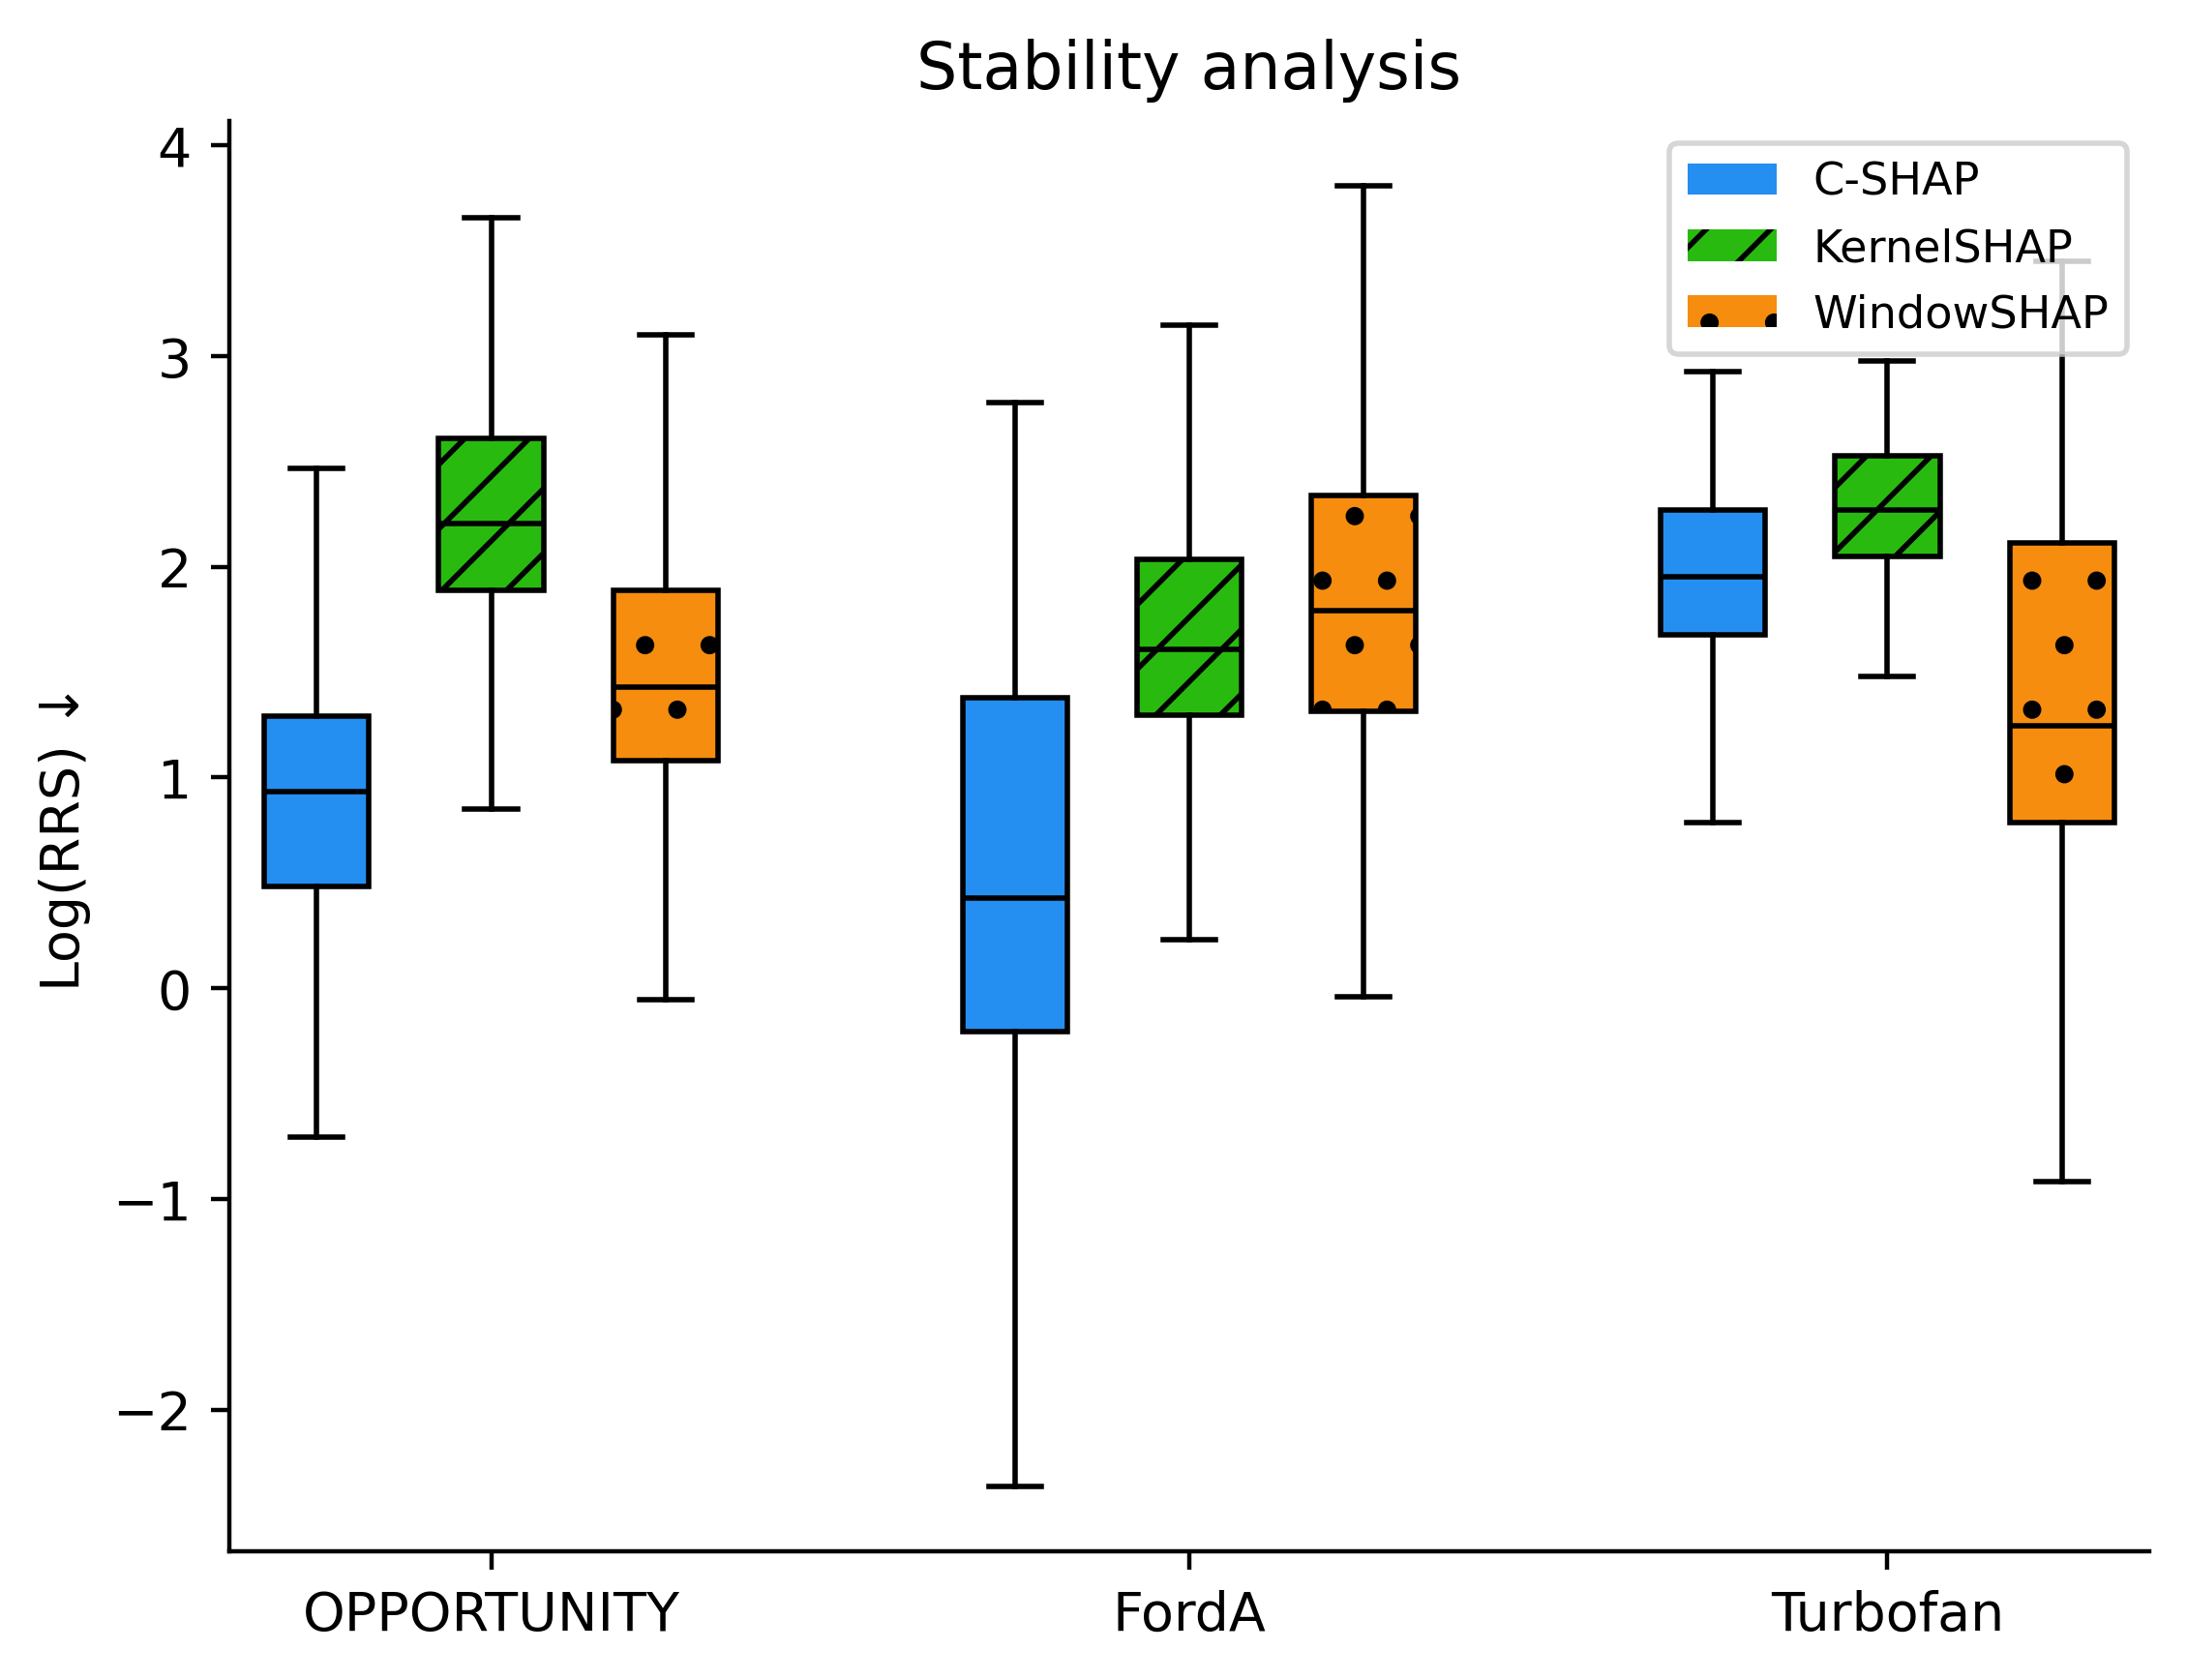

In [21]:
# Initialize figure
fig, ax = plt.subplots(dpi=400)

# Create boxplots representing the results for the different samples in each dataset
boxplot_opp = ax.boxplot([rrs_nn_features['opportunity_uni']['cshap_custom'], 
                                rrs_nn_features['opportunity_uni']['kernelshap'],
                                rrs_nn_features['opportunity_uni']['windowshap_sliding']],
                      positions=np.array(range(3)),  
                      widths=0.6, patch_artist=True, showfliers=False, medianprops=dict(color='black'))

boxplot_forda = ax.boxplot([rrs_nn_features['fordA']['cshap_custom'], 
                                rrs_nn_features['fordA']['kernelshap'],
                                rrs_nn_features['fordA']['windowshap_sliding']],
                      positions=np.array(range(3)) + 4,  
                      widths=0.6, patch_artist=True, showfliers=False, medianprops=dict(color='black'))

boxplot_turbo = ax.boxplot([rrs_nn_features['turbofan']['cshap_custom'], 
                                rrs_nn_features['turbofan']['kernelshap'],
                                rrs_nn_features['turbofan']['windowshap_sliding']],
                      positions=np.array(range(3)) + 8,  
                      widths=0.6, patch_artist=True, showfliers=False, medianprops=dict(color='black'))

# Add hatches and colors to barplots
hatches = [None, '//', '.']
sub_colors = [colors[1], colors[2], colors[3]]
for patch, color, hatch in zip(boxplot_opp['boxes'], sub_colors, hatches):
    patch.set_facecolor(color)
    patch.set_hatch(hatch)

for patch, color, hatch in zip(boxplot_forda['boxes'], sub_colors, hatches):
    patch.set_facecolor(color)
    patch.set_hatch(hatch)

for patch, color, hatch in zip(boxplot_turbo['boxes'], sub_colors, hatches):
    patch.set_facecolor(color)
    patch.set_hatch(hatch)

# Put dataset names as x ticks
ax.set_xticks([1, 5, 9])
ax.set_xticklabels(['OPPORTUNITY', 'FordA', 'Turbofan'])

# Set legend
legend_elements = [Patch(facecolor=colors[1], label='C-SHAP'), 
                   Patch(facecolor=colors[2], label='KernelSHAP', hatch='//'),
                   Patch(facecolor=colors[3], label='WindowSHAP', hatch='.')]

# Annotate figure
ax.set_title('Stability analysis')
ax.set_ylabel('Log(RRS) ↓')
ax.legend(handles=legend_elements, loc='upper right', fontsize='small')

# Remove spines
ax.spines.right.set_visible(False)
ax.spines.top.set_visible(False)

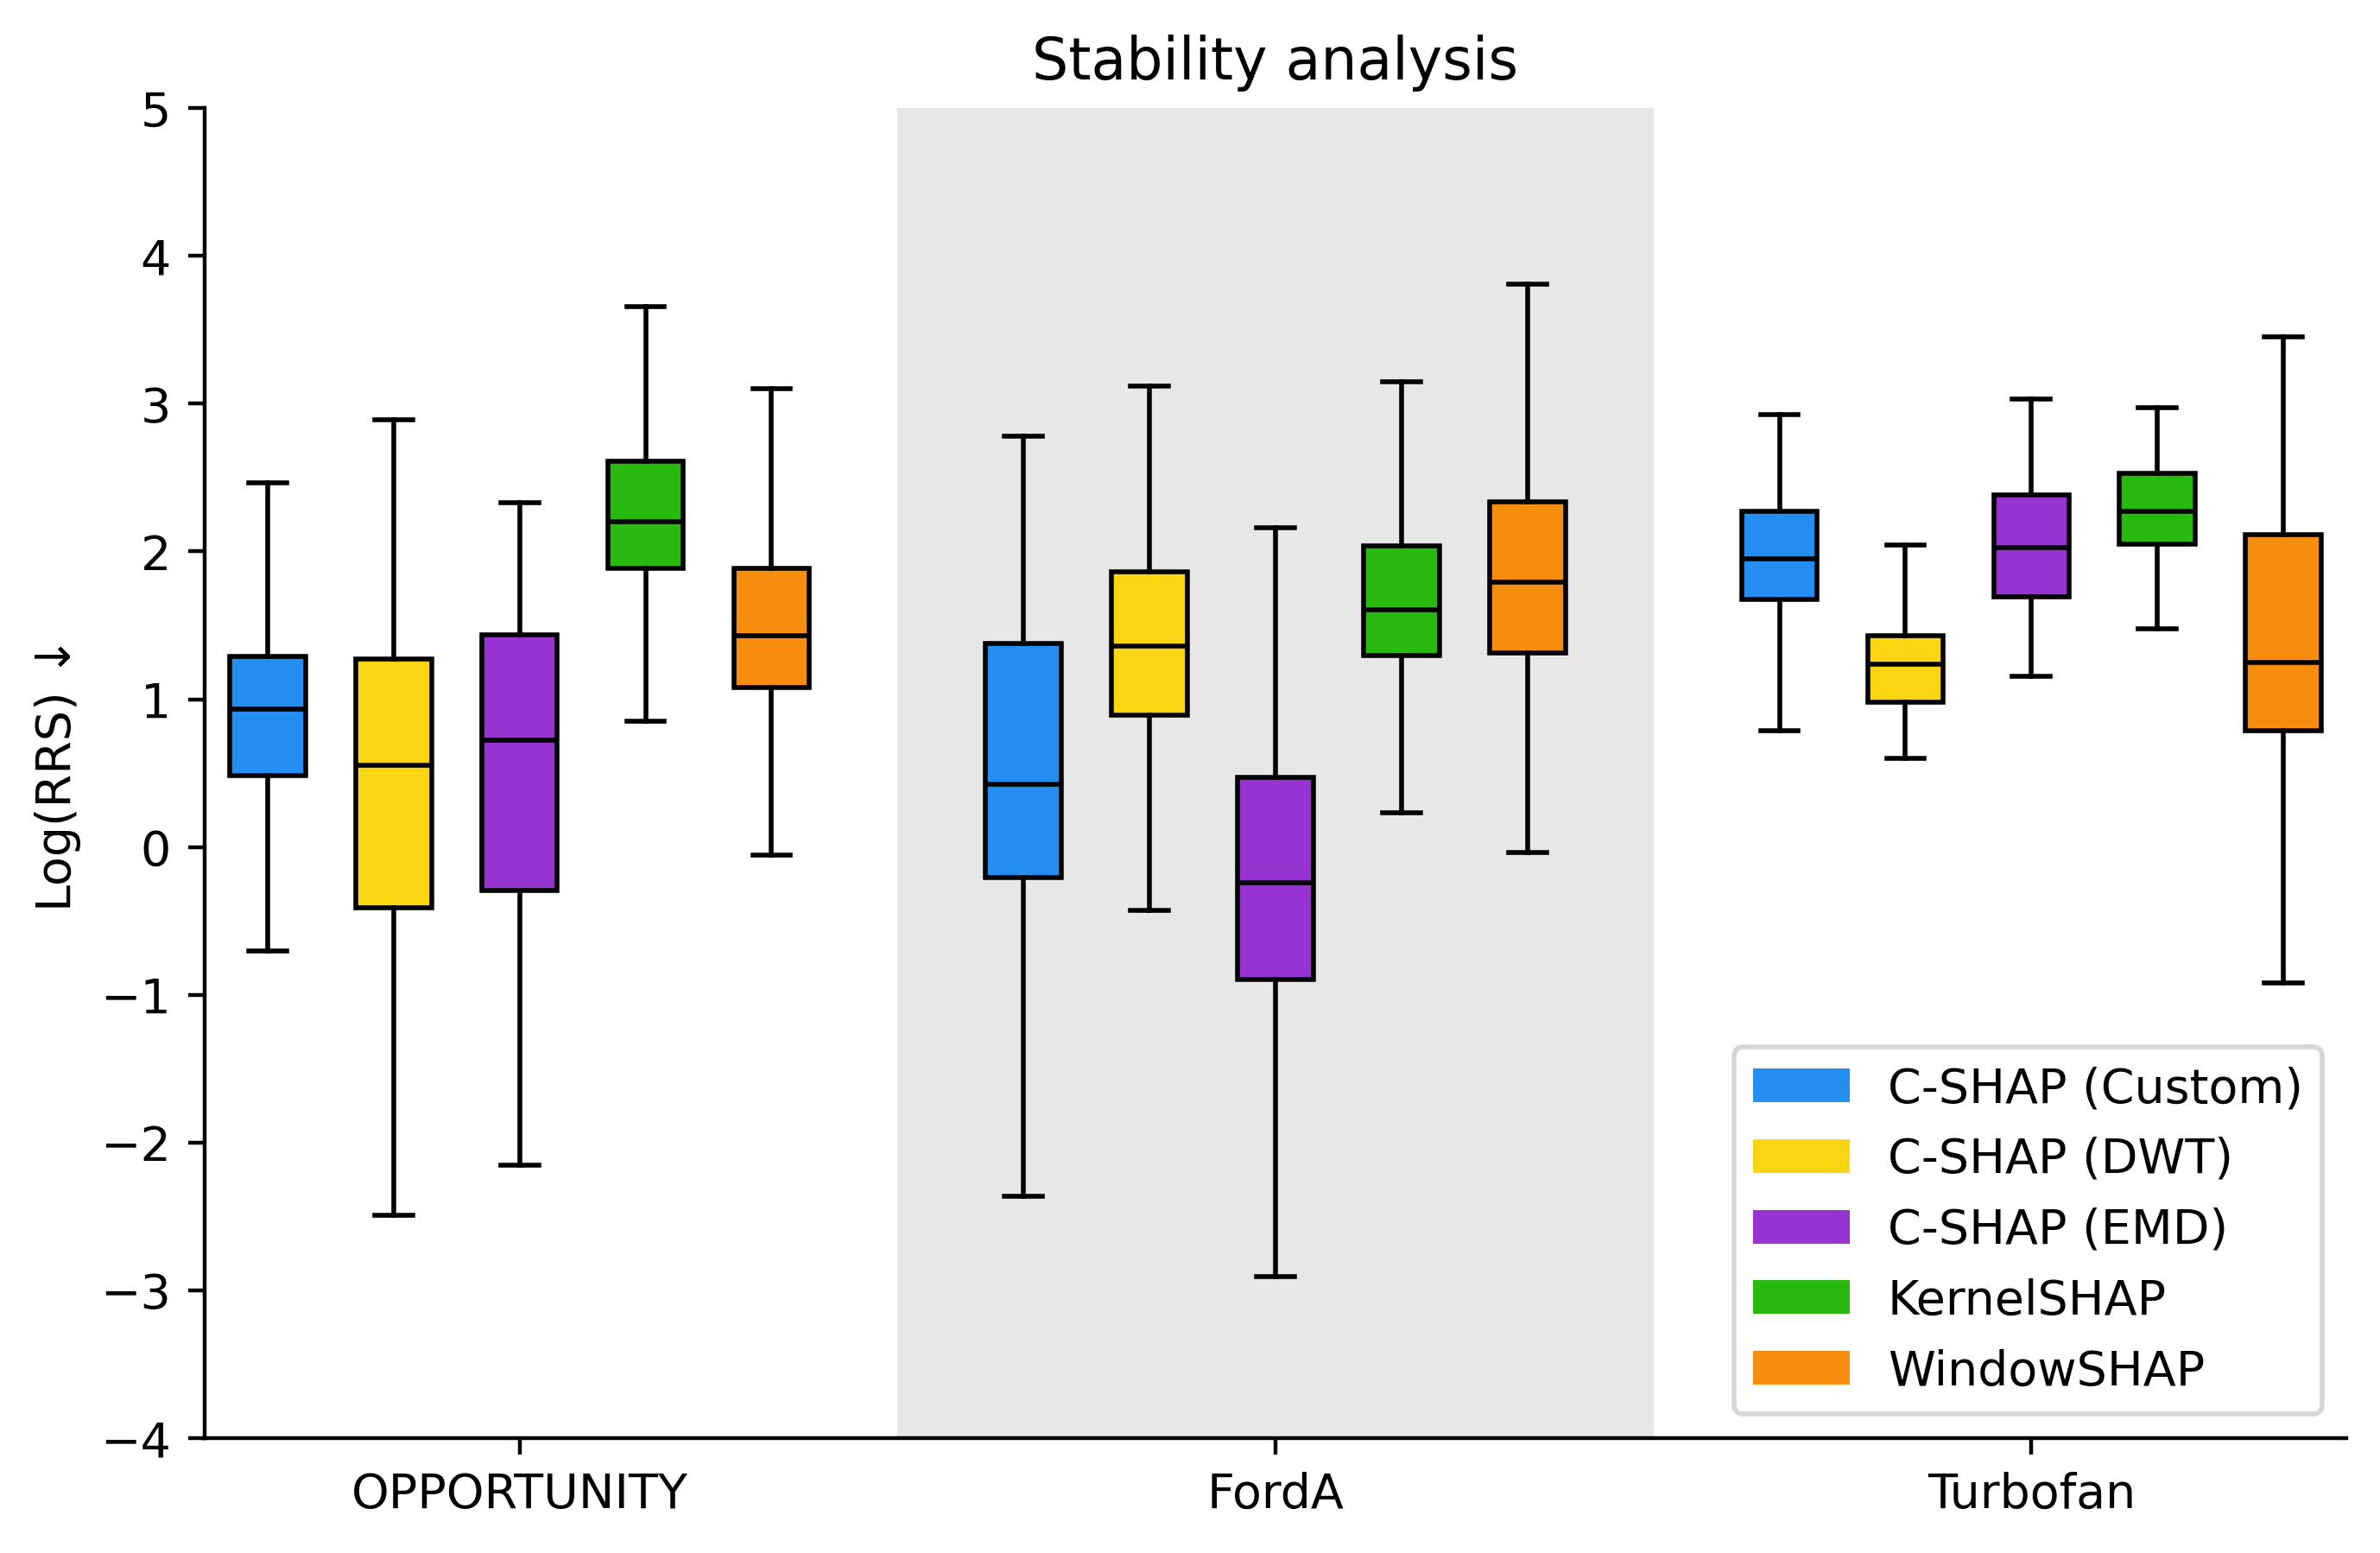

In [22]:
# Initialize figure
fig, ax = plt.subplots(dpi=400, figsize=(8, 5.))

plt.axvspan(5, 11, facecolor='#D0D0D0', alpha=0.5)

# Create boxplots representing the results for the different samples in each dataset
boxplot_opp = ax.boxplot([rrs_nn_features['opportunity_uni']['cshap_custom'], 
                                rrs_nn_features['opportunity_uni']['cshap_dwt'],
                                rrs_nn_features['opportunity_uni']['cshap_emd'],
                                rrs_nn_features['opportunity_uni']['kernelshap'],
                                rrs_nn_features['opportunity_uni']['windowshap_sliding']],
                      positions=np.array(range(5)),  
                      widths=0.6, patch_artist=True, showfliers=False, medianprops=dict(color='black'))

boxplot_forda = ax.boxplot([rrs_nn_features['fordA']['cshap_custom'], 
                                rrs_nn_features['fordA']['cshap_dwt'],
                                rrs_nn_features['fordA']['cshap_emd'],
                                rrs_nn_features['fordA']['kernelshap'],
                                rrs_nn_features['fordA']['windowshap_sliding']],
                      positions=np.array(range(5)) + 6,  
                      widths=0.6, patch_artist=True, showfliers=False, medianprops=dict(color='black'))

boxplot_turbo = ax.boxplot([rrs_nn_features['turbofan']['cshap_custom'], 
                                rrs_nn_features['turbofan']['cshap_dwt'],
                                rrs_nn_features['turbofan']['cshap_emd'],
                                rrs_nn_features['turbofan']['kernelshap'],
                                rrs_nn_features['turbofan']['windowshap_sliding']],
                      positions=np.array(range(5)) + 12,  
                      widths=0.6, patch_artist=True, showfliers=False, medianprops=dict(color='black'))

# Add hatches and colors to barplots
# hatches = [None, '//', '.']
sub_colors = [colors[1], colors[0], colors[4], colors[2], colors[3]]
for patch, color in zip(boxplot_opp['boxes'], sub_colors):
    patch.set_facecolor(color)

for patch, color in zip(boxplot_forda['boxes'], sub_colors):
    patch.set_facecolor(color)

for patch, color in zip(boxplot_turbo['boxes'], sub_colors):
    patch.set_facecolor(color)

# Manually set vertical limits
plt.ylim(-4, 5)

# Put dataset names as x ticks
ax.set_xticks([2, 8, 14])
ax.set_xticklabels(['OPPORTUNITY', 'FordA', 'Turbofan'])

# Set legend
legend_elements = [Patch(facecolor=colors[1], label='C-SHAP (Custom)'),
                   Patch(facecolor=colors[0], label='C-SHAP (DWT)'),
                   Patch(facecolor=colors[4], label='C-SHAP (EMD)'), 
                   Patch(facecolor=colors[2], label='KernelSHAP'),
                   Patch(facecolor=colors[3], label='WindowSHAP')]

# Annotate figure
ax.set_title('Stability analysis')
ax.set_ylabel('Log(RRS) ↓')
ax.legend(handles=legend_elements, loc='lower right')

# Remove spines
ax.spines.right.set_visible(False)
ax.spines.top.set_visible(False)